# What each group of inputs adds

The static benchmark of notebooks 02 to 07 uses nine inputs in three groups: **geometry** (distance, concrete and wood walls), **channel** (frequency) and **environment** (CO2, humidity, PM2.5, pressure, temperature). Reviewers asked for the contribution of each group and for distance-only and wall-only baselines. They also asked for the benchmark with and without the SNR of the same packet, the predictor of the submitted manuscript; that subset is included for the record, although a predictor that is only known once the packet has been received cannot serve a link budget. Part B asks the same of the groups that the history rungs add.

**Part A, static groups.** One LightGBM, tuned separately on every subset of inputs (30 candidates of a Bayesian search on every tenth training row, validation folds kept), so that a subset is not penalised by hyperparameters chosen for the full set. The per-link mean, the training mean of each link, is the reference without a model. Scores on the hold-out and over the five forward folds: RMSE, and the 99 % margin from one shift with its pinball loss. Differences against the full model and against the per-link mean come with 95 % intervals from resampling days. The SNR of the predicted packet is also compared link by link, against the SNR at which each link operates.

**Part B, history groups.** The same paired comparison for every step of the history rungs and every model family, from the saved residuals of notebooks 02 to 15. The 99 % shift is taken from the validation packets at SF7 to SF10, the regime of the hold-out.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from skopt import BayesSearchCV
from skopt.space import Integer, Real
from history_features import RUNGS
from margin_tools import pinball, shift_pooled, day_codes, boot_stat

RANDOM_STATE = 42
TAU = 0.99

In [2]:
# Part A. The chronological split and forward-chaining folds of notebook 00 (fold -1 = first training block, 0-4 = validation blocks, 9 = hold-out)
train = pd.read_csv("Data_Files/train.csv")
train["fold"] = np.load("Data_Files/train_folds.npy")
test = pd.read_csv("Data_Files/test.csv")
test["fold"] = 9
s = pd.concat([train, test], ignore_index=True)
s["t"] = pd.to_datetime(s["time"], utc=True, format="mixed")
fold, PL, link = s["fold"].to_numpy(), s["PL"].to_numpy(), s["device_id"].to_numpy()
day = day_codes(s["t"])
GEOMETRY, CHANNEL, ENVIRONMENT = ["distance", "c_walls", "w_walls"], ["frequency"], ["co2", "humidity", "pm25", "pressure", "temperature"]
subsets = {"distance only": ["distance"],
           "geometry": GEOMETRY,
           "geometry + channel": GEOMETRY + CHANNEL,
           "geometry + environment": GEOMETRY + ENVIRONMENT,
           "geometry + channel + environment": GEOMETRY + CHANNEL + ENVIRONMENT,       # the benchmark
           "benchmark + SNR of the same packet": GEOMETRY + CHANNEL + ENVIRONMENT + ["snr"],   # the leaky variant of the submitted manuscript, for the record
           "environment only": ENVIRONMENT}
full = "geometry + channel + environment"
print(f"{(fold < 9).sum():,} training packets, {(fold == 9).sum():,} on the hold-out; subsets: {list(subsets)}")

2,128,219 training packets, 532,055 on the hold-out; subsets: ['distance only', 'geometry', 'geometry + channel', 'geometry + environment', 'geometry + channel + environment', 'benchmark + SNR of the same packet', 'environment only']


In [3]:
# One search per subset (the search space of notebook 05), then the out-of-fold and hold-out predictions
space = {"num_leaves": Integer(8, 96), "max_depth": Integer(1, 10), "learning_rate": Real(0.01, 0.10, prior="log-uniform"), "n_estimators": Integer(100, 1200),
         "min_child_samples": Integer(200, 5000), "min_child_weight": Real(1e-3, 30.0, prior="log-uniform"), "subsample": Real(0.6, 0.9),
         "colsample_bytree": Real(0.4, 0.9), "reg_alpha": Real(1e-4, 50.0, prior="log-uniform"), "reg_lambda": Real(1e-4, 50.0, prior="log-uniform")}
sub = np.flatnonzero(fold < 9)[::10]
cv_sub = [(np.flatnonzero(fold[sub] < k), np.flatnonzero(fold[sub] == k)) for k in range(5)]
base = dict(subsample_freq=1, force_col_wise=True, random_state=RANDOM_STATE, verbose=-1)

def oof_and_test(make, X):
    p = np.full(len(s), np.nan)
    for k in range(5):
        tr, va = fold < k, fold == k
        p[va] = make().fit(X[tr], PL[tr]).predict(X[va])
    p[fold == 9] = make().fit(X[fold < 9], PL[fold < 9]).predict(X[fold == 9])
    return p

pred, best = {}, {}
for name, cols in subsets.items():
    t0 = time.time()
    X = s[cols].to_numpy()
    bs = BayesSearchCV(lgb.LGBMRegressor(n_jobs=4, **base), space, n_iter=30, cv=cv_sub, scoring="neg_root_mean_squared_error", n_jobs=8, n_points=2,
                       random_state=RANDOM_STATE, refit=False, optimizer_kwargs={"n_initial_points": 10})
    bs.fit(X[sub], PL[sub])
    best[name] = dict(bs.best_params_)
    pred[name] = oof_and_test(lambda: lgb.LGBMRegressor(n_jobs=8, **base, **best[name]), X)
    print(f"{name}: search RMSE {-bs.best_score_:.3f} dB, {time.time() - t0:.0f} s")
json.dump(best, open("CV_Results/static_group_best_params.json", "w"), indent=1, default=float)

# the reference without a model: each link's mean over the earlier training packets
mean = np.full(len(s), np.nan)
for k in list(range(5)) + [9]:
    earlier = s[fold < k] if k < 9 else s[fold < 9]
    mean[fold == k] = s.loc[fold == k, "device_id"].map(earlier.groupby("device_id")["PL"].mean())
pred["per-link mean"] = mean
overall = np.full(len(s), np.nan)                       # and one mean for all links: no inputs at all
for k in list(range(5)) + [9]:
    overall[fold == k] = s.loc[fold < k if k < 9 else fold < 9, "PL"].mean()
pred["global mean"] = overall

distance only: search RMSE 6.242 dB, 44 s


geometry: search RMSE 6.239 dB, 47 s


geometry + channel: search RMSE 6.218 dB, 88 s


geometry + environment: search RMSE 6.286 dB, 73 s


geometry + channel + environment: search RMSE 6.267 dB, 53 s


benchmark + SNR of the same packet: search RMSE 6.170 dB, 82 s


environment only: search RMSE 17.018 dB, 28 s


In [4]:
# Scores: RMSE on the hold-out and over the validation folds, and the 99 % margin from one shift
val, ev = (fold >= 0) & (fold < 9), fold == 9
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
rows = []
for name, p in pred.items():
    e = PL - p
    folds = [rmse(e[fold == k]) for k in range(5)]
    c = shift_pooled(e[val], TAU)
    rows.append({"inputs": name, "hold-out RMSE": rmse(e[ev]), "validation RMSE": rmse(e[val]), "fold RMSE mean": np.mean(folds), "fold RMSE sd": np.std(folds, ddof=1),
                 "99 % shift dB": c, "coverage": float((e[ev] <= c).mean()), "pinball x 1000": 1000 * pinball(e[ev], c, TAU).mean()})
scores = pd.DataFrame(rows).set_index("inputs")

# paired differences on the hold-out: against the full model and against the per-link mean
te = np.flatnonzero(ev)
dd = pd.factorize(day[te])[0]
def diff(a, b):
    ea, eb = (PL - pred[a])[te], (PL - pred[b])[te]
    ca, cb = shift_pooled((PL - pred[a])[val], TAU), shift_pooled((PL - pred[b])[val], TAU)
    r = boot_stat(dd, np.column_stack([ea ** 2, eb ** 2, np.ones(len(te))]), lambda T: np.sqrt(T[:, 0] / T[:, 2]) - np.sqrt(T[:, 1] / T[:, 2]))
    l = boot_stat(dd, np.column_stack([pinball(ea, ca, TAU) - pinball(eb, cb, TAU), np.ones(len(te))]), lambda T: 1000 * T[:, 0] / T[:, 1])
    return r + l
for ref in (full, "geometry + channel", "per-link mean"):
    columns = [f"dRMSE vs {ref}", f"lo ({ref})", f"hi ({ref})", f"dpinball vs {ref}", f"lo p ({ref})", f"hi p ({ref})"]
    scores = scores.join(pd.DataFrame({n: diff(n, ref) for n in pred if n != ref}, index=columns).T)
scores.to_csv("CV_Results/static_feature_groups.csv")
display(scores.iloc[:, :7].round(3))
for ref in (full, "geometry + channel", "per-link mean"):
    print(f"hold-out RMSE minus that of {ref}, with the 95 % interval (negative: better)")
    display(scores[[f"dRMSE vs {ref}", f"lo ({ref})", f"hi ({ref})"]].dropna().round(3))

,hold-out RMSE,validation RMSE,fold RMSE mean,fold RMSE sd,99 % shift dB,coverage,pinball x 1000
inputs,,,,,,,
distance only,4.859,6.261,6.220,0.796,17.941,0.998,204.645
geometry,4.861,6.261,6.220,0.800,17.993,0.998,205.105
geometry + channel,4.845,6.239,6.193,0.847,18.194,0.998,207.954
geometry + environment,4.745,6.307,6.255,0.910,18.438,0.998,206.307
geometry + channel + environment,4.766,6.300,6.244,0.943,18.276,0.998,205.236
benchmark + SNR of the same packet,4.701,6.230,6.162,1.022,18.404,0.997,201.376
environment only,15.993,17.082,17.070,0.704,35.316,0.999,373.871
per-link mean,4.943,6.312,6.264,0.867,18.184,0.998,207.534
global mean,16.354,17.381,17.364,0.849,33.658,0.999,355.283


hold-out RMSE minus that of geometry + channel + environment, with the 95 % interval (negative: better)


,dRMSE vs geometry + channel + environment,lo (geometry + channel + environment),hi (geometry + channel + environment)
inputs,,,
distance only,0.093,-0.054,0.235
geometry,0.095,-0.049,0.232
geometry + channel,0.080,-0.030,0.187
geometry + environment,-0.020,-0.119,0.074
benchmark + SNR of the same packet,-0.065,-0.174,0.036
environment only,11.227,10.705,11.718
per-link mean,0.177,0.066,0.284
global mean,11.588,11.059,12.069


hold-out RMSE minus that of geometry + channel, with the 95 % interval (negative: better)


,dRMSE vs geometry + channel,lo (geometry + channel),hi (geometry + channel)
inputs,,,
distance only,0.014,-0.036,0.063
geometry,0.015,-0.030,0.060
geometry + environment,-0.100,-0.145,-0.061
geometry + channel + environment,-0.080,-0.187,0.030
benchmark + SNR of the same packet,-0.145,-0.344,0.053
environment only,11.147,10.685,11.577
per-link mean,0.098,0.081,0.115
global mean,11.509,11.064,11.934


hold-out RMSE minus that of per-link mean, with the 95 % interval (negative: better)


,dRMSE vs per-link mean,lo (per-link mean),hi (per-link mean)
inputs,,,
distance only,-0.084,-0.139,-0.028
geometry,-0.082,-0.134,-0.031
geometry + channel,-0.098,-0.115,-0.081
geometry + environment,-0.198,-0.252,-0.149
geometry + channel + environment,-0.177,-0.284,-0.066
benchmark + SNR of the same packet,-0.242,-0.447,-0.043
environment only,11.050,10.588,11.487
global mean,11.411,10.962,11.845


In [5]:
# The SNR of the predicted packet, link by link: the SNR at which each link operates and the slope of its path loss on that SNR (training packets),
# against the hold-out RMSE of the static model without and with that SNR, with 95 % intervals from resampling days
without, with_ = full, "benchmark + SNR of the same packet"
snr = s["snr"].to_numpy()
rows = []
for l in ["all"] + sorted(np.unique(link[te])):
    i = te if l == "all" else te[link[te] == l]
    j = (fold < 9) & np.isfinite(snr)
    if l != "all":
        j &= link == l
    e0, e1 = (PL - pred[without])[i], (PL - pred[with_])[i]
    r = boot_stat(pd.factorize(day[i])[0], np.column_stack([e1 ** 2, e0 ** 2, np.ones(len(i))]), lambda T: np.sqrt(T[:, 0] / T[:, 2]) - np.sqrt(T[:, 1] / T[:, 2]))
    rows.append({"link": l, "hold-out packets": len(i), "median SNR dB": np.median(snr[j]), "SNR 10 %": np.percentile(snr[j], 10), "SNR 90 %": np.percentile(snr[j], 90),
                 "path loss per dB of SNR": np.polyfit(snr[j], PL[j], 1)[0] if l != "all" else np.nan,
                 "RMSE without": rmse(e0), "RMSE with": rmse(e1), "difference": r[0], "lo": r[1], "hi": r[2]})
leak = pd.DataFrame(rows).set_index("link")
leak.to_csv("CV_Results/static_snr_leak.csv")
display(leak.round(3))

,hold-out packets,median SNR dB,SNR 10 %,SNR 90 %,path loss per dB of SNR,RMSE without,RMSE with,difference,lo,hi
link,,,,,,,,,,
all,532055,9.8,7.5,12.2,NaN,4.766,4.701,-0.065,-0.174,0.036
ED0,89116,10.2,8.0,12.5,0.321,4.927,4.821,-0.105,-0.250,0.047
ED1,88573,10.0,8.0,12.5,-0.167,5.115,5.610,0.495,0.053,0.900
ED2,89123,10.0,8.0,12.5,0.280,5.137,5.245,0.108,0.009,0.201
ED3,87215,10.5,8.2,12.8,0.115,4.376,4.046,-0.330,-0.437,-0.219
ED4,88648,10.0,7.8,12.2,0.091,3.878,3.912,0.034,-0.120,0.222
ED5,89380,8.2,5.0,10.8,-0.772,5.016,4.312,-0.704,-0.828,-0.575


In [6]:
# How much of a difference between subsets is the tuning itself: the search and the fits repeated with other seeds
rows = []
for name in (full, "geometry + environment"):
    X = s[subsets[name]].to_numpy()
    for seed in (1, 2, 3):
        bs = BayesSearchCV(lgb.LGBMRegressor(n_jobs=4, **dict(base, random_state=seed)), space, n_iter=30, cv=cv_sub, scoring="neg_root_mean_squared_error", n_jobs=8, n_points=2,
                           random_state=seed, refit=False, optimizer_kwargs={"n_initial_points": 10})
        bs.fit(X[sub], PL[sub])
        p = oof_and_test(lambda: lgb.LGBMRegressor(n_jobs=8, **dict(base, random_state=seed), **dict(bs.best_params_)), X)
        rows.append(dict(inputs=name, seed=seed, hold_out_rmse=rmse((PL - p)[ev])))
noise = pd.DataFrame(rows)
noise.to_csv("CV_Results/static_tuning_noise.csv", index=False)
print("hold-out RMSE of the same inputs after a repeated search and fit")
display(noise.pivot(index="seed", columns="inputs", values="hold_out_rmse").round(3))
display(noise.groupby("inputs").hold_out_rmse.agg(["mean", "std"]).round(3))

hold-out RMSE of the same inputs after a repeated search and fit


inputs,geometry + channel + environment,geometry + environment
seed,,
1,4.739,4.811
2,4.747,4.747
3,4.767,4.795


,mean,std
inputs,,
geometry + channel + environment,4.751,0.014
geometry + environment,4.785,0.033


In [7]:
# Part B. The history rungs: the rows of notebooks 13 to 16 and the saved residuals of every family
train = pd.read_csv("Data_Files/history_train.csv")
test = pd.read_csv("Data_Files/history_test.csv")
d = pd.concat([train, test], ignore_index=True)
d["t"] = pd.to_datetime(d["t"], utc=True)
d = d.sort_values("t").reset_index(drop=True)
f2 = d["fold"].to_numpy()
H = {k.split()[0]: v for k, v in RUNGS.items()}
ok = (d["y"].notna() & d[H["H7"]].notna().all(axis=1)).to_numpy()
sf = d["SF"].to_numpy().astype(int)
val2, ev2 = ok & (f2 >= 0) & (f2 < 9), ok & (f2 == 9)
position = pd.Series(np.arange(len(d)), index=pd.MultiIndex.from_arrays([d["device_id"], d["t"]]))

def residuals(name):
    out = np.full(len(d), np.nan)
    for split in ("oof", "test"):
        r = pd.read_csv(f"Residuals/residuals_{name}_{split}.csv", usecols=["time", "device_id", "resid_db"])
        i = position.reindex(pd.MultiIndex.from_arrays([r["device_id"], pd.to_datetime(r["time"], utc=True)])).to_numpy()
        found = ~np.isnan(i)
        out[i[found].astype(int)] = r["resid_db"].to_numpy()[found]
    return out

static_name = {"Linear": "MLR", "RF": "RF", "XGB": "XGB", "LGBM": "LGBM", "KNN": "KNN", "ANN": "ANN"}
res = {}
for fam in ("Linear", "RF", "XGB", "LGBM", "KNN", "ANN"):
    if fam in static_name:
        res[(fam, "static")] = residuals(static_name[fam])
    for rung in ("H1", "H2", "H3", "H4", "H5", "H6", "H7"):
        res[(fam, rung)] = residuals(f"{fam}_{rung}")
common = ev2 & np.all([np.isfinite(r) for r in res.values()], axis=0)
print(f"{len(res)} models; hold-out packets common to all: {common.sum():,}")

48 models; hold-out packets common to all: 531,983


In [8]:
# Paired differences between consecutive rungs, hold-out, 95 % intervals from resampling days
te = np.flatnonzero(common)
dd = pd.factorize(pd.factorize(d["t"].dt.floor("D"), sort=True)[0][te])[0]
shift = {k: shift_pooled(r[val2 & (sf <= 10) & np.isfinite(r)], TAU) for k, r in res.items()}       # SF7-10 validation packets, the hold-out regime
def step(fam, a, b):
    ea, eb = res[(fam, a)][te], res[(fam, b)][te]
    r = boot_stat(dd, np.column_stack([eb ** 2, ea ** 2, np.ones(len(te))]), lambda T: np.sqrt(T[:, 0] / T[:, 2]) - np.sqrt(T[:, 1] / T[:, 2]))
    l = boot_stat(dd, np.column_stack([pinball(eb, shift[(fam, b)], TAU) - pinball(ea, shift[(fam, a)], TAU), np.ones(len(te))]), lambda T: 1000 * T[:, 0] / T[:, 1])
    return dict(family=fam, step=f"{a} to {b}", dRMSE=r[0], rmse_lo=r[1], rmse_hi=r[2], dpinball=l[0], pin_lo=l[1], pin_hi=l[2])
coarse = [("static", "H1"), ("H1", "H4"), ("H4", "H6"), ("H6", "H7")]
fine = [("H1", "H2"), ("H2", "H3"), ("H3", "H4"), ("H4", "H5"), ("H5", "H6"), ("H6", "H7")]
rows = [step(f, a, b) for f in ("Linear", "RF", "XGB", "LGBM", "KNN", "ANN") for a, b in coarse + fine if (f, a) in res and (f, b) in res]
steps = pd.DataFrame(rows).drop_duplicates(["family", "step"])
steps["excludes zero"] = np.where((steps.rmse_lo > 0) | (steps.rmse_hi < 0), "yes", "no")
steps.to_csv("CV_Results/history_group_steps.csv", index=False)
print("hold-out RMSE of the later rung minus the earlier rung (dB, negative: the added inputs help), with the 95 % interval")
display(steps.set_index(["family", "step"]).round(3))

hold-out RMSE of the later rung minus the earlier rung (dB, negative: the added inputs help), with the 95 % interval


dRMSE  rmse_lo  rmse_hi  dpinball   pin_lo   pin_hi  \
family step                                                                
Linear static to H1 -2.883   -3.095   -2.682  -120.109 -129.833 -113.525   
       H1 to H4     -0.136   -0.146   -0.126    -2.553   -2.815   -2.317   
       H4 to H6     -0.002   -0.003   -0.002    -0.152   -0.191   -0.113   
       H6 to H7     -0.000   -0.001    0.000     0.070    0.002    0.130   
       H1 to H2     -0.128   -0.138   -0.118    -2.537   -2.799   -2.300   
       H2 to H3     -0.000   -0.000   -0.000    -0.051   -0.063   -0.038   
       H3 to H4     -0.007   -0.008   -0.007     0.034    0.017    0.051   
       H4 to H5     -0.002   -0.002   -0.002    -0.086   -0.114   -0.058   
       H5 to H6     -0.001   -0.001   -0.000    -0.067   -0.085   -0.047   
RF     static to H1 -2.561   -2.824   -2.307  -118.308 -130.530 -110.365   
       H1 to H4     -0.378   -0.396   -0.358    -8.124   -8.681   -7.576   
       H4 to H6     -0.001   -0.001    0.000     0.002   -0.025    0.030   
       H6 to H7     -0.000   -0.002    0.001    -0.386   -0.504   -0.264   
       H1 to H2     -0.147   -0.158   -0.137    -2.249   -2.525   -1.962   
       H2 to H3     -0.001   -0.001   -0.000    -0.167   -0.219   -0.118   
       H3 to H4     -0.230   -0.242   -0.216    -5.709   -6.102   -5.286   
       H4 to H5     -0.001   -0.002   -0.001    -0.017   -0.048    0.009   
       H5 to H6      0.001    0.000    0.001     0.019   -0.002    0.042   
XGB    static to H1 -2.564   -2.789   -2.354  -119.443 -127.133 -113.732   
       H1 to H4     -0.406   -0.422   -0.389    -9.479   -9.991   -8.953   
       H4 to H6     -0.001   -0.001    0.000     0.080    0.018    0.140   
       H6 to H7     -0.001   -0.002    0.000    -0.551   -0.763   -0.312   
       H1 to H2     -0.224   -0.236   -0.213    -4.031   -4.366   -3.693   
       H2 to H3      0.004    0.002    0.005    -0.204   -0.287   -0.124   
       H3 to H4     -0.186   -0.194   -0.177    -5.244   -5.565   -4.907   
       H4 to H5     -0.001   -0.002   -0.001    -0.019   -0.087    0.050   
       H5 to H6      0.001    0.000    0.002     0.099    0.047    0.154   
LGBM   static to H1 -2.607   -2.829   -2.401  -120.450 -128.203 -114.741   
       H1 to H4     -0.390   -0.407   -0.372    -9.565  -10.106   -9.045   
       H4 to H6     -0.003   -0.004   -0.002    -0.004   -0.084    0.075   
       H6 to H7      0.000   -0.001    0.001    -0.688   -0.970   -0.386   
       H1 to H2     -0.265   -0.279   -0.252    -5.242   -5.577   -4.900   
       H2 to H3     -0.002   -0.003   -0.001    -0.143   -0.201   -0.091   
       H3 to H4     -0.122   -0.129   -0.116    -4.179   -4.491   -3.848   
       H4 to H5     -0.004   -0.005   -0.003    -0.140   -0.214   -0.069   
       H5 to H6      0.002    0.001    0.002     0.136    0.080    0.193   
KNN    static to H1 -2.388   -2.666   -2.116  -110.745 -126.289 -101.153   
       H1 to H4     -0.328   -0.344   -0.312    -6.509   -6.921   -6.092   
       H4 to H6      0.048    0.043    0.052     1.453    1.298    1.605   
       H6 to H7      0.029    0.026    0.032     0.754    0.604    0.919   
       H1 to H2     -0.166   -0.176   -0.155    -2.831   -3.118   -2.524   
       H2 to H3      0.025    0.023    0.028     0.116   -0.022    0.247   
       H3 to H4     -0.188   -0.197   -0.178    -3.794   -4.057   -3.534   
       H4 to H5      0.016    0.015    0.018     0.476    0.369    0.585   
       H5 to H6      0.031    0.027    0.036     0.976    0.821    1.135   
ANN    static to H1 -2.205   -2.469   -1.950  -110.380 -120.762 -103.354   
       H1 to H4     -0.475   -0.495   -0.455   -11.087  -11.603  -10.569   
       H4 to H6     -0.022   -0.025   -0.020    -0.716   -0.827   -0.617   
       H6 to H7      0.004    0.001    0.006     0.044   -0.127    0.236   
       H1 to H2     -0.184   -0.194   -0.174    -3.498   -3.771   -3.217   
       H2 to H3     -0.010   -0.011   -0.008    -0.652   -0.740   -0.

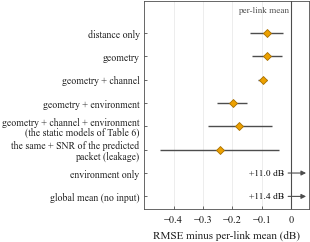

In [9]:
# Figure: the static subsets, hold-out RMSE minus that of the per-link mean with the 95 % interval from resampling days; the two subsets without
# the geometry lie off the scale and are marked by their value
import paper_figures as pf
pf.use()
ROWS = [("distance only", "distance only"), ("geometry", "geometry"), ("geometry + channel", "geometry + channel"),
        ("geometry + environment", "geometry + environment"), (full, "geometry + channel + environment\n(the static models of Table 6)"),
        ("benchmark + SNR of the same packet", "the same + SNR of the predicted\npacket (leakage)"), ("environment only", "environment only"),
        ("global mean", "global mean (no input)")]
right = 0.06
fig = plt.figure(figsize=(pf.COLUMN, 2.6))
ax = fig.add_axes([0.5, 0.16, 0.47, 0.8])
for i, (name, _) in enumerate(ROWS):
    value, lo, hi = scores.loc[name, ["dRMSE vs per-link mean", "lo (per-link mean)", "hi (per-link mean)"]]
    if value > right:                                                            # off the scale: an arrow and the value
        ax.annotate("", xy=(right, i), xytext=(right - 0.08, i), arrowprops=dict(arrowstyle="-|>", color=pf.INK2, lw=0.8, mutation_scale=7))
        ax.text(right - 0.085, i, f"+{value:.1f} dB", ha="right", va="center", fontsize=6.8)
        continue
    assert -0.5 < lo and hi < right                                              # the interval lies inside the axis
    ax.plot([lo, hi], [i, i], color=pf.INK2, lw=1.0, solid_capstyle="butt", zorder=2)
    ax.plot(value, i, marker="D", ms=4.0, mfc=pf.AMBER, mec=pf.AMBER_DARK, mew=0.6, ls="none", zorder=3)
ax.axvline(0, color=pf.INK2, lw=0.8, zorder=1)
ax.text(-0.008, -0.95, "per-link mean", ha="right", va="center", fontsize=6.6, color=pf.INK2)
ax.set_yticks(range(len(ROWS)))
ax.set_yticklabels([label for _, label in ROWS], fontsize=7, linespacing=1.0)
ax.set_ylim(len(ROWS) - 0.45, -1.35)
ax.set_xlim(-0.5, right)
ax.set_xticks([-0.4, -0.3, -0.2, -0.1, 0])
ax.set_xticklabels(["−0.4", "−0.3", "−0.2", "−0.1", "0"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("RMSE minus per-link mean (dB)")
fig.savefig("Figures/feature_groups.png")
plt.show()

**Reading of the results.**

**Part A, static inputs.**
* **Every subset that holds the geometry, and not the SNR of the same packet, lands within 0.20 dB of the per-link mean.** Hold-out RMSE is 4.75 to 4.86 dB against 4.94 dB for the per-link mean, and the intervals from resampling days exclude zero. The whole range is as large as the noise of the tuning: repeating the search and the fits for the same inputs moves the hold-out RMSE by up to 0.07 dB.
* **Distance only is a control.** With six links it takes six values, so it is the per-link mean up to the shrinkage of the trees, and it still lands 0.08 dB below it. Differences of that size are not resolved by this design.
* **The environment adds about 0.1 dB, not resolved from zero.** Added to the geometry it lowers the hold-out RMSE from 4.86 to 4.75 dB; added to geometry and channel, by 0.08 dB, with an interval from -0.19 to +0.03. Both are of the order of the tuning noise. The sensors alone are useless for the level: the RMSE is 15.99 dB against 16.35 dB for one mean over all links and 4.94 dB for the per-link mean, so they remove 4 % of the variance around one mean for all links where the link identity removes 91 %.
* **The SNR of the same packet, the predictor of the submitted manuscript, is worth 0.07 dB here, not resolved from zero.** Added to the benchmark it lowers the hold-out RMSE from 4.77 to 4.70 dB (interval -0.17 to +0.04) and raises the 99 % shift from 18.28 to 18.40 dB. Link by link it ranges from -0.70 dB on ED5, the weakest link (median SNR 8.2 dB, path loss -0.77 dB per dB of SNR), to +0.49 dB on ED1, where the added input makes the model worse; every link operates at a median SNR of 8.2 to 10.5 dB. It is known only once the packet has been received, so it cannot enter a link budget; on the public datasets the same leak is worth 0.64 dB (Medellín) and 0.53 dB (campus), notebooks 19 and 21.
* **No subset improves the margin.** The 99 % shift from one pooled calibration is 17.9 to 18.4 dB for every subset with the geometry, 18.2 dB for the per-link mean, and the pinball losses lie within 4 % of each other.

**Part B, the inputs of the history rungs.**
* **The link's history is the step.** It lowers the RMSE by 2.20 to 2.88 dB in every family (the ANN, the best static model, gains the least), with intervals 0.41 to 0.55 dB wide.
* **Of the groups that follow, the same-channel history matters in every family and the spreading factor in every family but the linear one; the rest change little or nothing.** The same-channel history is worth -0.13 (linear) to -0.27 dB (LightGBM), the spreading factor -0.01 (linear) to -0.28 dB (ANN), the SNR of earlier packets -0.03 (ANN) to +0.02 dB (kNN). The clock, the sensors and the link level with the geometry change the RMSE by at most 0.03 dB in any family; the kNN gets worse with them by up to 0.03 dB, the usual price of uninformative inputs in a distance-based method.
* **Limits of the intervals.** They cover the sampling of the hold-out and not the training noise, which is 0.01 to 0.1 dB. Steps of 0.1 dB and more are resolved; steps of a few thousandths of a dB are statistically different from zero in the paired comparison and practically zero.